In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, '/home/biel')
sys.path.insert(0, '/home/biel/Hi-COLA')
sys.path.insert(0, '/home/biel/Hi-COLA/scripts')
sys.path.insert(0, '/home/biel/HODDIES')
for module_name in list(sys.modules):
    if module_name == 'HODDIES' or module_name.startswith('HODDIES.'):
        del sys.modules[module_name]

import numpy as np
import matplotlib.pyplot as plt
from HODDIES import HOD
from abacus_reference_cosmology import SERIALIZABLE_PARAMETERS, PARAMETERS
import HODDIES

print(f'Using HODDIES from {HODDIES.__file__}')


Using HODDIES from /home/biel/HODDIES/HODDIES/__init__.py


In [2]:
from cosmoprimo.fiducial import Cosmology

abacus_cosmo = Cosmology(
    Omega0_m=SERIALIZABLE_PARAMETERS['Omega_m'],
    Omega_b=SERIALIZABLE_PARAMETERS['Omega_b'],
    h=SERIALIZABLE_PARAMETERS['h'],
    sigma8=SERIALIZABLE_PARAMETERS['sigma8'],
    n_s=SERIALIZABLE_PARAMETERS['n_s'],
    w0_fld=SERIALIZABLE_PARAMETERS['w0'],
    wa_fld=SERIALIZABLE_PARAMETERS['wa'],
    T_cmb=SERIALIZABLE_PARAMETERS['Tcmb0_K'],
    N_eff=SERIALIZABLE_PARAMETERS['Neff'],
    m_ncdm=[],
    engine='class',
)

print(SERIALIZABLE_PARAMETERS)
abacus_cosmo.get_params()


{'H0_km_s_Mpc': 67.36, 'h': 0.6736, 'Omega_m': 0.315192, 'Omega_cdm': 0.26589, 'Omega_b': 0.049302, 'Omega_Lambda': 0.684808, 'Tcmb0_K': 2.726, 'Neff': 3.046, 'n_s': 0.9649, 'A_s': 2.083e-09, 'sigma8': 0.811355, 'w0': -1.0, 'wa': 0.0}


{'Omega_k': 0.0,
 'k_pivot': 0.05,
 'alpha_s': 0.0,
 'beta_s': 0.0,
 'r': 0.0,
 'n_t': -0.0,
 'alpha_t': -0.0,
 'T_ncdm_over_cmb': array([], dtype=float64),
 'tau_reio': 0.06,
 'reionization_width': 0.5,
 'A_L': 1.0,
 'cs2_fld': array(1.),
 'non_linear': '',
 'modes': ['s'],
 'lensing': False,
 'z_pk': array([ 0.        ,  0.01189061,  0.04756243,  0.10701546,  0.1902497 ,
         0.29726516,  0.42806183,  0.58263971,  0.76099881,  0.96313912,
         1.18906064,  1.43876338,  1.71224732,  2.00951249,  2.33055886,
         2.67538644,  3.04399524,  3.43638526,  3.85255648,  4.29250892,
         4.75624257,  5.24375743,  5.75505351,  6.2901308 ,  6.8489893 ,
         7.43162901,  8.03804994,  8.66825208,  9.32223543, 10.        ]),
 'kmax_pk': 10.0,
 'ellmax_cl': 2500,
 'YHe': 'BBN',
 'use_ppf': True,
 'Omega_b': array(0.049302),
 'h': array(0.6736),
 'sigma8': array(0.811355),
 'n_s': 0.9649,
 'w0_fld': array(-1.),
 'wa_fld': array(0.),
 'T_cmb': array(2.726),
 'N_ur': array(3.046),


In [ ]:
boxsize = 500.0
redshift = 0.500
model = 'nDGP_Abacus'

OUTPUT_DIR = Path(f'/scratch/biel/{model}/snapshot_{model}_z{redshift:.3f}/halo_catalog')
HALO_CATALOG = OUTPUT_DIR / 'halos200c_catalog.npy'
HALO_METADATA = Path(str(HALO_CATALOG) + '.json')
HODDIES_CATALOG = OUTPUT_DIR / 'halos200c_hoddies.npy'
HMF_OUTPUT = OUTPUT_DIR / 'halos200c_hmf.txt'
ANALYSIS_DIR = OUTPUT_DIR / 'analysis'
PARAM_FILE = '/home/biel/Hi-COLA/Notebooks/HOD_parameter_file_z{:.3f}.yaml'.format(redshift)

print(f'Halo catalog: {HALO_CATALOG}')
print(f'HODDIES catalog: {HODDIES_CATALOG}')
print(f'HMF output: {HMF_OUTPUT}')
print(f'Analysis directory: {ANALYSIS_DIR}')


Halo catalog: /scratch/biel/nDGP_Abacus/snapshot_nDGP_Abacus_z0.500/halo_catalog/halos200c_catalog.npy
HODDIES catalog: /scratch/biel/nDGP_Abacus/snapshot_nDGP_Abacus_z0.500/halo_catalog/halos200c_hoddies.npy
HMF output: /scratch/biel/nDGP_Abacus/snapshot_nDGP_Abacus_z0.500/halo_catalog/halos200c_hmf.txt
Analysis directory: /scratch/biel/nDGP_Abacus/snapshot_nDGP_Abacus_z0.500/halo_catalog/analysis


In [4]:
if not HODDIES_CATALOG.exists():
    raise FileNotFoundError(
        f'Missing {HODDIES_CATALOG}. Run /home/biel/Hi-COLA/halo_finder512_abacus.sh first, '
        'then come back to this notebook.'
    )

arr = np.load(HODDIES_CATALOG)
print(f'Loaded {len(arr):,} HODDIES-ready halos')
print(arr.dtype)

if HALO_METADATA.exists():
    with HALO_METADATA.open() as f:
        halo_metadata = json.load(f)
    print(json.dumps(halo_metadata, indent=2))
else:
    halo_metadata = {}

expected_cosmology = SERIALIZABLE_PARAMETERS
halo_cosmology = halo_metadata.get('cosmology')
if halo_cosmology is not None:
    mismatches = {
        key: (halo_cosmology.get(key), expected)
        for key, expected in expected_cosmology.items()
        if key in halo_cosmology and not np.isclose(float(halo_cosmology[key]), float(expected))
    }
    if mismatches:
        raise ValueError(f'Halo catalog cosmology metadata does not match AbacusSummit c000 reference: {mismatches}')
else:
    print('Halo catalog metadata has no cosmology block; using notebook AbacusSummit c000 reference cosmology.')


Loaded 912,050 HODDIES-ready halos
[('x', '<f8'), ('y', '<f8'), ('z', '<f8'), ('vx', '<f8'), ('vy', '<f8'), ('vz', '<f8'), ('Mh', '<f8'), ('log10_Mh', '<f8'), ('Rh', '<f8'), ('Rs', '<f8'), ('c', '<f8'), ('Vrms', '<f8'), ('halo_id', '<i8')]
{
  "boxsize": 500.0,
  "cosmology": {
    "A_s": 2.083e-09,
    "H0_km_s_Mpc": 67.36,
    "Neff": 3.046,
    "Omega_Lambda": 0.684808,
    "Omega_b": 0.049302,
    "Omega_cdm": 0.26589,
    "Omega_m": 0.315192,
    "Tcmb0_K": 2.726,
    "h": 0.6736,
    "n_s": 0.9649,
    "sigma8": 0.811355,
    "w0": -1.0,
    "wa": 0.0
  },
  "cosmology_source": "AbacusSummit c000 (Planck2018), https://abacussummit.readthedocs.io/en/latest/cosmologies.html",
  "fields": [
    "x",
    "y",
    "z",
    "vx",
    "vy",
    "vz",
    "m200c",
    "log10_m200c",
    "r200c",
    "rs",
    "c",
    "vrms",
    "length",
    "halo_id"
  ],
  "halos": 912050,
  "linking_length": 0.2,
  "mass_field": "m200c",
  "mass_units": "Msun/h",
  "mdef": "200c",
  "mpi_ranks": 512

In [5]:
print('Mass range:', arr['Mh'].min(), arr['Mh'].max())
print('log10_Mh range:', arr['log10_Mh'].min(), arr['log10_Mh'].max())
print('Position mins:', np.min(np.vstack([arr['x'], arr['y'], arr['z']]).T, axis=0))
print('Position maxs:', np.max(np.vstack([arr['x'], arr['y'], arr['z']]).T, axis=0))


Mass range: 519366831960.3477 1447475360673489.2
log10_Mh range: 11.715474211068127 15.160611179781432
Position mins: [0.00013695 0.00028854 0.00030618]
Position maxs: [499.99996948 499.99978638 499.9984436 ]


In [6]:
HOD_obj = HOD(hcat_file=arr, **{'hcat': {'boxsize': boxsize}}, param_file=PARAM_FILE)
HOD_obj.args['hcat']['z_simu'] = redshift
HOD_obj.args['cosmo'].update({
    'fiducial_cosmo': None,
    'engine': 'class',
    'h': SERIALIZABLE_PARAMETERS['h'],
    'Omega_m': SERIALIZABLE_PARAMETERS['Omega_m'],
    'Omega_cdm': SERIALIZABLE_PARAMETERS['Omega_cdm'],
    'Omega_L': SERIALIZABLE_PARAMETERS['Omega_Lambda'],
    'Omega_b': SERIALIZABLE_PARAMETERS['Omega_b'],
    'sigma_8': SERIALIZABLE_PARAMETERS['sigma8'],
    'n_s': SERIALIZABLE_PARAMETERS['n_s'],
    'w0_fdl': SERIALIZABLE_PARAMETERS['w0'],
    'wa_fdl': SERIALIZABLE_PARAMETERS['wa'],
})
HOD_obj.cosmo = abacus_cosmo


Set number of threads to 32


Initialize custom cosmology from the "cosmo" parameters


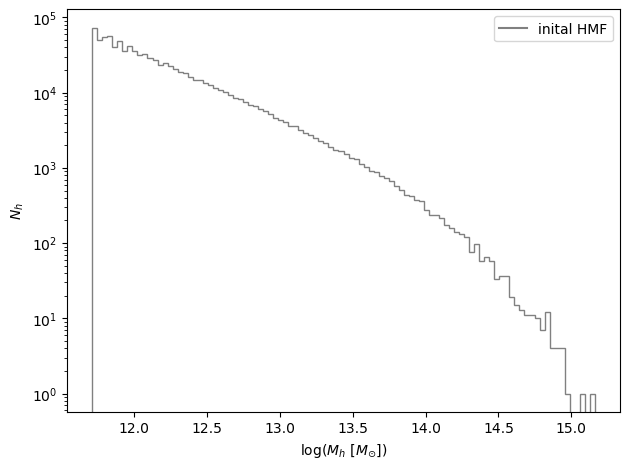

In [7]:
HOD_obj.plot_initial_HMF()

In [8]:
cat = HOD_obj.make_mock_cat(tracers='LRG', fix_seed=42)

Create mock catalog for ['LRG']


Run HOD for LRG


Set density to 0.0007 gal/Mpc/h


/home/biel/HODDIES/HODDIES/hod.py:884: UserWarning: Ac=1.0469495265308786 is > 1, the density is not fixed to 0.0007
  warnings.warn('Ac={} is > 1, the density is not fixed to {}'.format(hod_list_param_cen[0]*ds, self.args[tracer]["density"]))


HOD Computed 4.510854959487915


Start satellite assignement


Satellite assignement done 2.6735453605651855


LRG mock catalogue done 2.6886963844299316


68172 central galaxies, 8846 satellites, fraction of satellite 0.11 


Done overall time  LRG 7.212222099304199


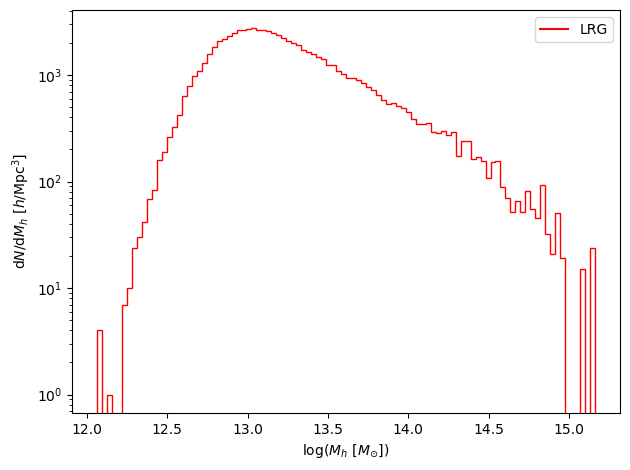

In [9]:
HOD_obj.plot_HMF(cat,tracer='LRG')

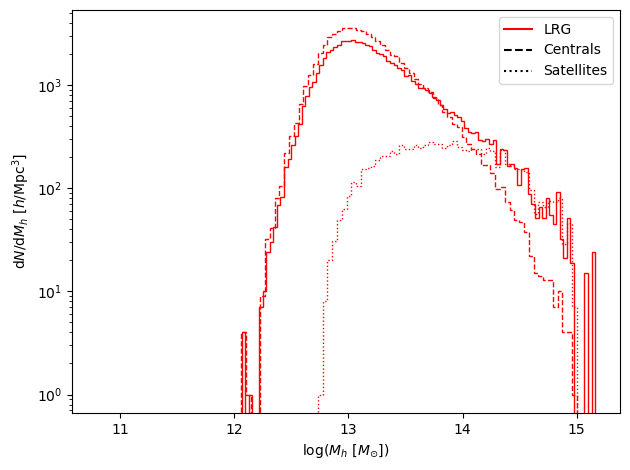

In [10]:
HOD_obj.plot_HMF(cat, show_sat=True, tracer='LRG')

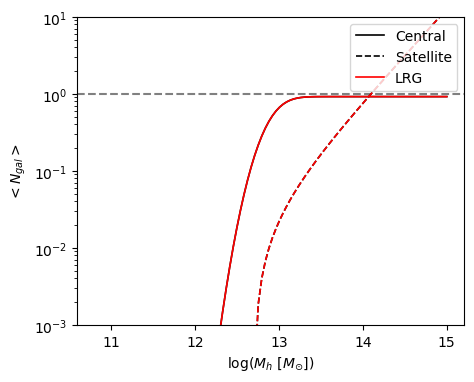

In [11]:
HOD_obj.HOD_plot()

## Styled plots (power_spectrum2 style)

In [12]:
FIG_SIZE = (6.6, 4.6)
LABEL_SIZE = 14.5
TICK_SIZE = 12.5
LEGEND_SIZE = 11.5
LINE_WIDTH = 1.9

COLA_COLOR = '#c47f2b'   # orange
BART_COLOR = '#1f4e79'   # navy
RATIO_COLOR = '#2b7a78'  # teal
REF_COLOR = '0.35'       # gray reference lines


def style_axis(ax, tick_size=TICK_SIZE):
    ax.minorticks_on()
    ax.grid(True, which='major', ls=':', color='0.82', alpha=0.75, lw=0.5)
    ax.tick_params(axis='both', which='major', direction='in', top=True, right=True,
                    labelsize=tick_size, length=4.6, width=0.95)
    ax.tick_params(axis='both', which='minor', direction='in', top=True, right=True,
                    labelsize=tick_size - 1.2, length=2.8, width=0.75)
    for spine in ax.spines.values():
        spine.set_linewidth(0.95)

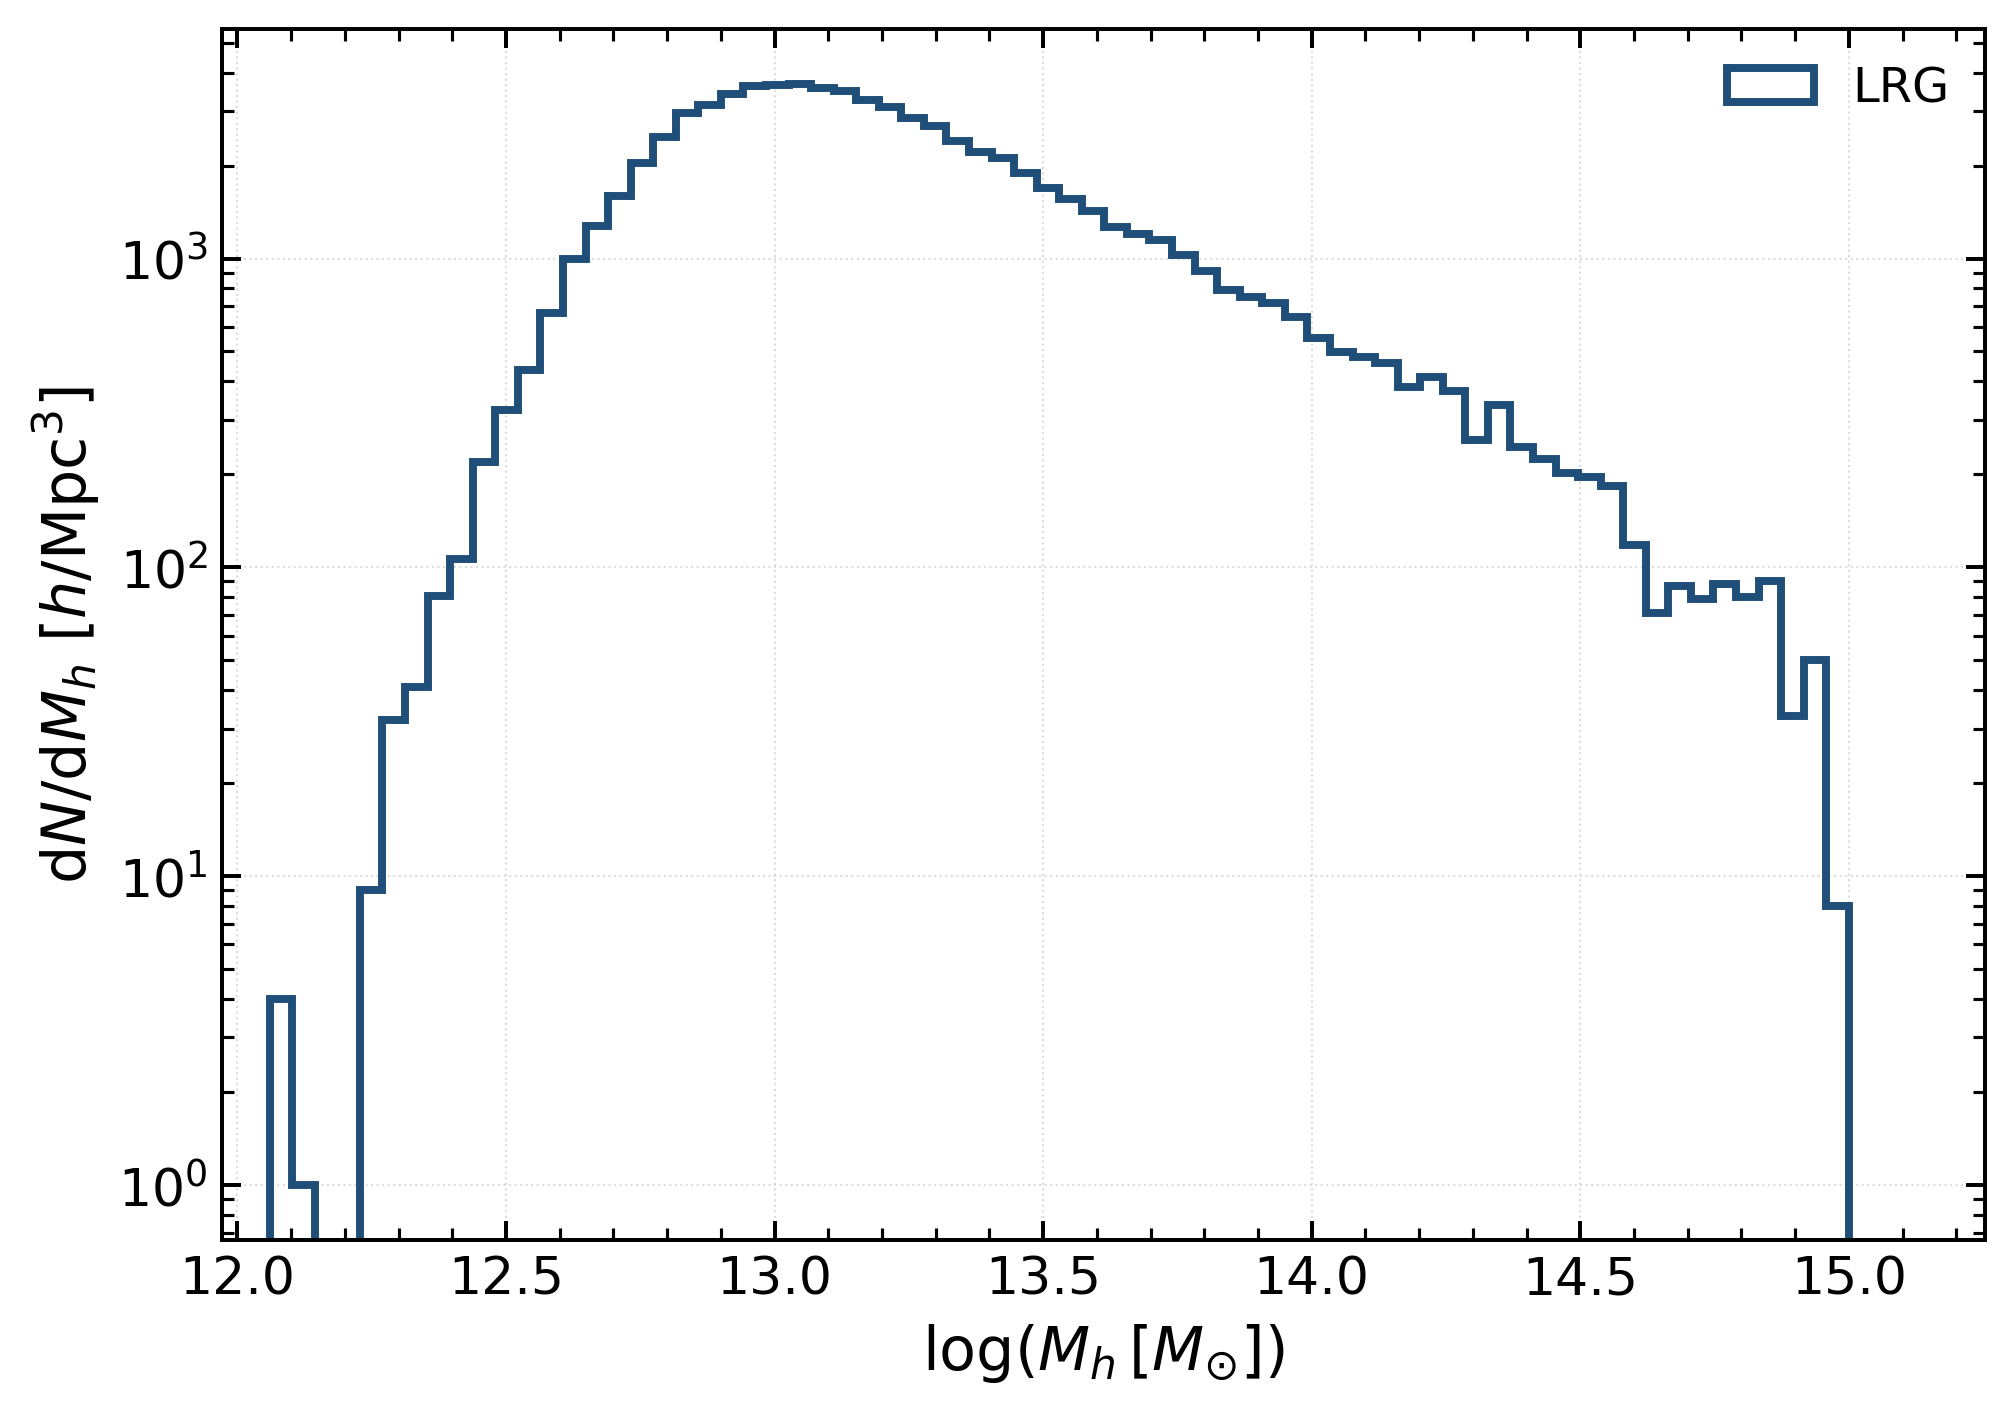

In [13]:
def plot_hmf_styled(cat, tracer='LRG', show_sat=False, mass_range=(10.8, 15), bins=100):
    mask = cat['TRACER'] == tracer
    data = cat['log10_Mh'][mask]

    fig, ax = plt.subplots(figsize=FIG_SIZE, dpi=300, constrained_layout=True)

    ax.hist(data, histtype='step', bins=bins, range=mass_range,
            color=BART_COLOR, lw=LINE_WIDTH, label=tracer)

    if show_sat:
        ax.hist(cat['log10_Mh'][mask & (cat['Central'] == 1)], histtype='step', bins=bins,
                range=mass_range, color=COLA_COLOR, lw=LINE_WIDTH, ls='--', label='Centrals')
        ax.hist(cat['log10_Mh'][mask & (cat['Central'] == 0)], histtype='step', bins=bins,
                range=mass_range, color=RATIO_COLOR, lw=LINE_WIDTH, ls=':', label='Satellites')

    ax.set_yscale('log')
    ax.set_xlabel(r'$\log(M_h\,[M_{\odot}])$', fontsize=LABEL_SIZE)
    ax.set_ylabel(r'd$N$/d$M_h$ [$h$/Mpc$^3$]', fontsize=LABEL_SIZE)
    ax.legend(fontsize=LEGEND_SIZE, frameon=False, handlelength=1.8, borderaxespad=0.35, labelspacing=0.35)

    pad = 0.03 * (data.max() - data.min())
    ax.set_xlim(data.min() - pad, data.max() + pad)

    style_axis(ax)
    plt.show()


plot_hmf_styled(cat, tracer='LRG')

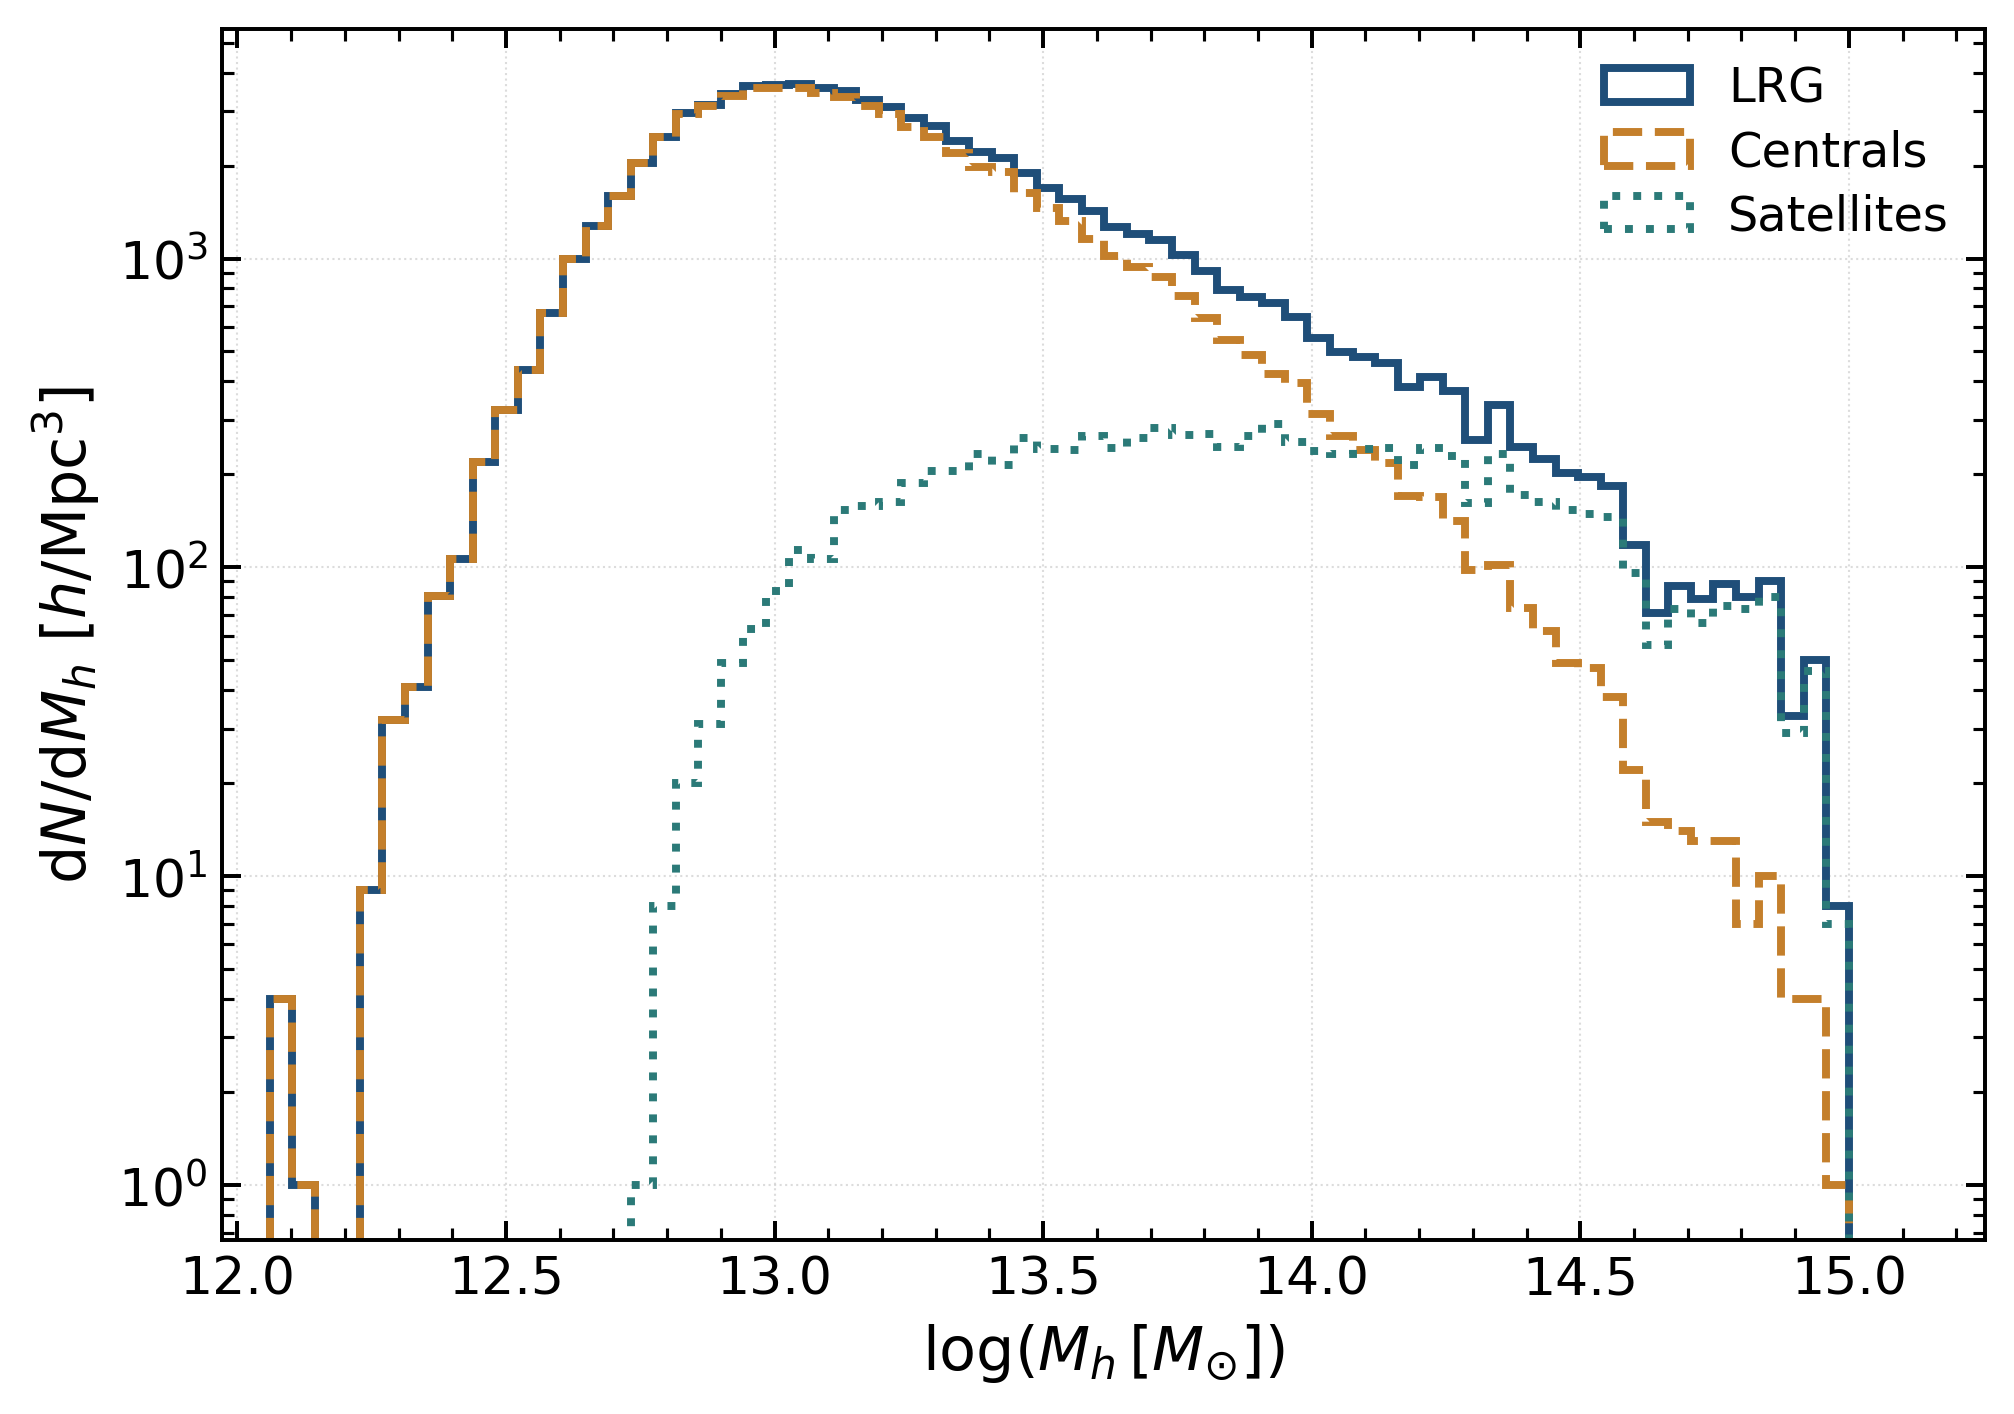

In [14]:
plot_hmf_styled(cat, tracer='LRG', show_sat=True)

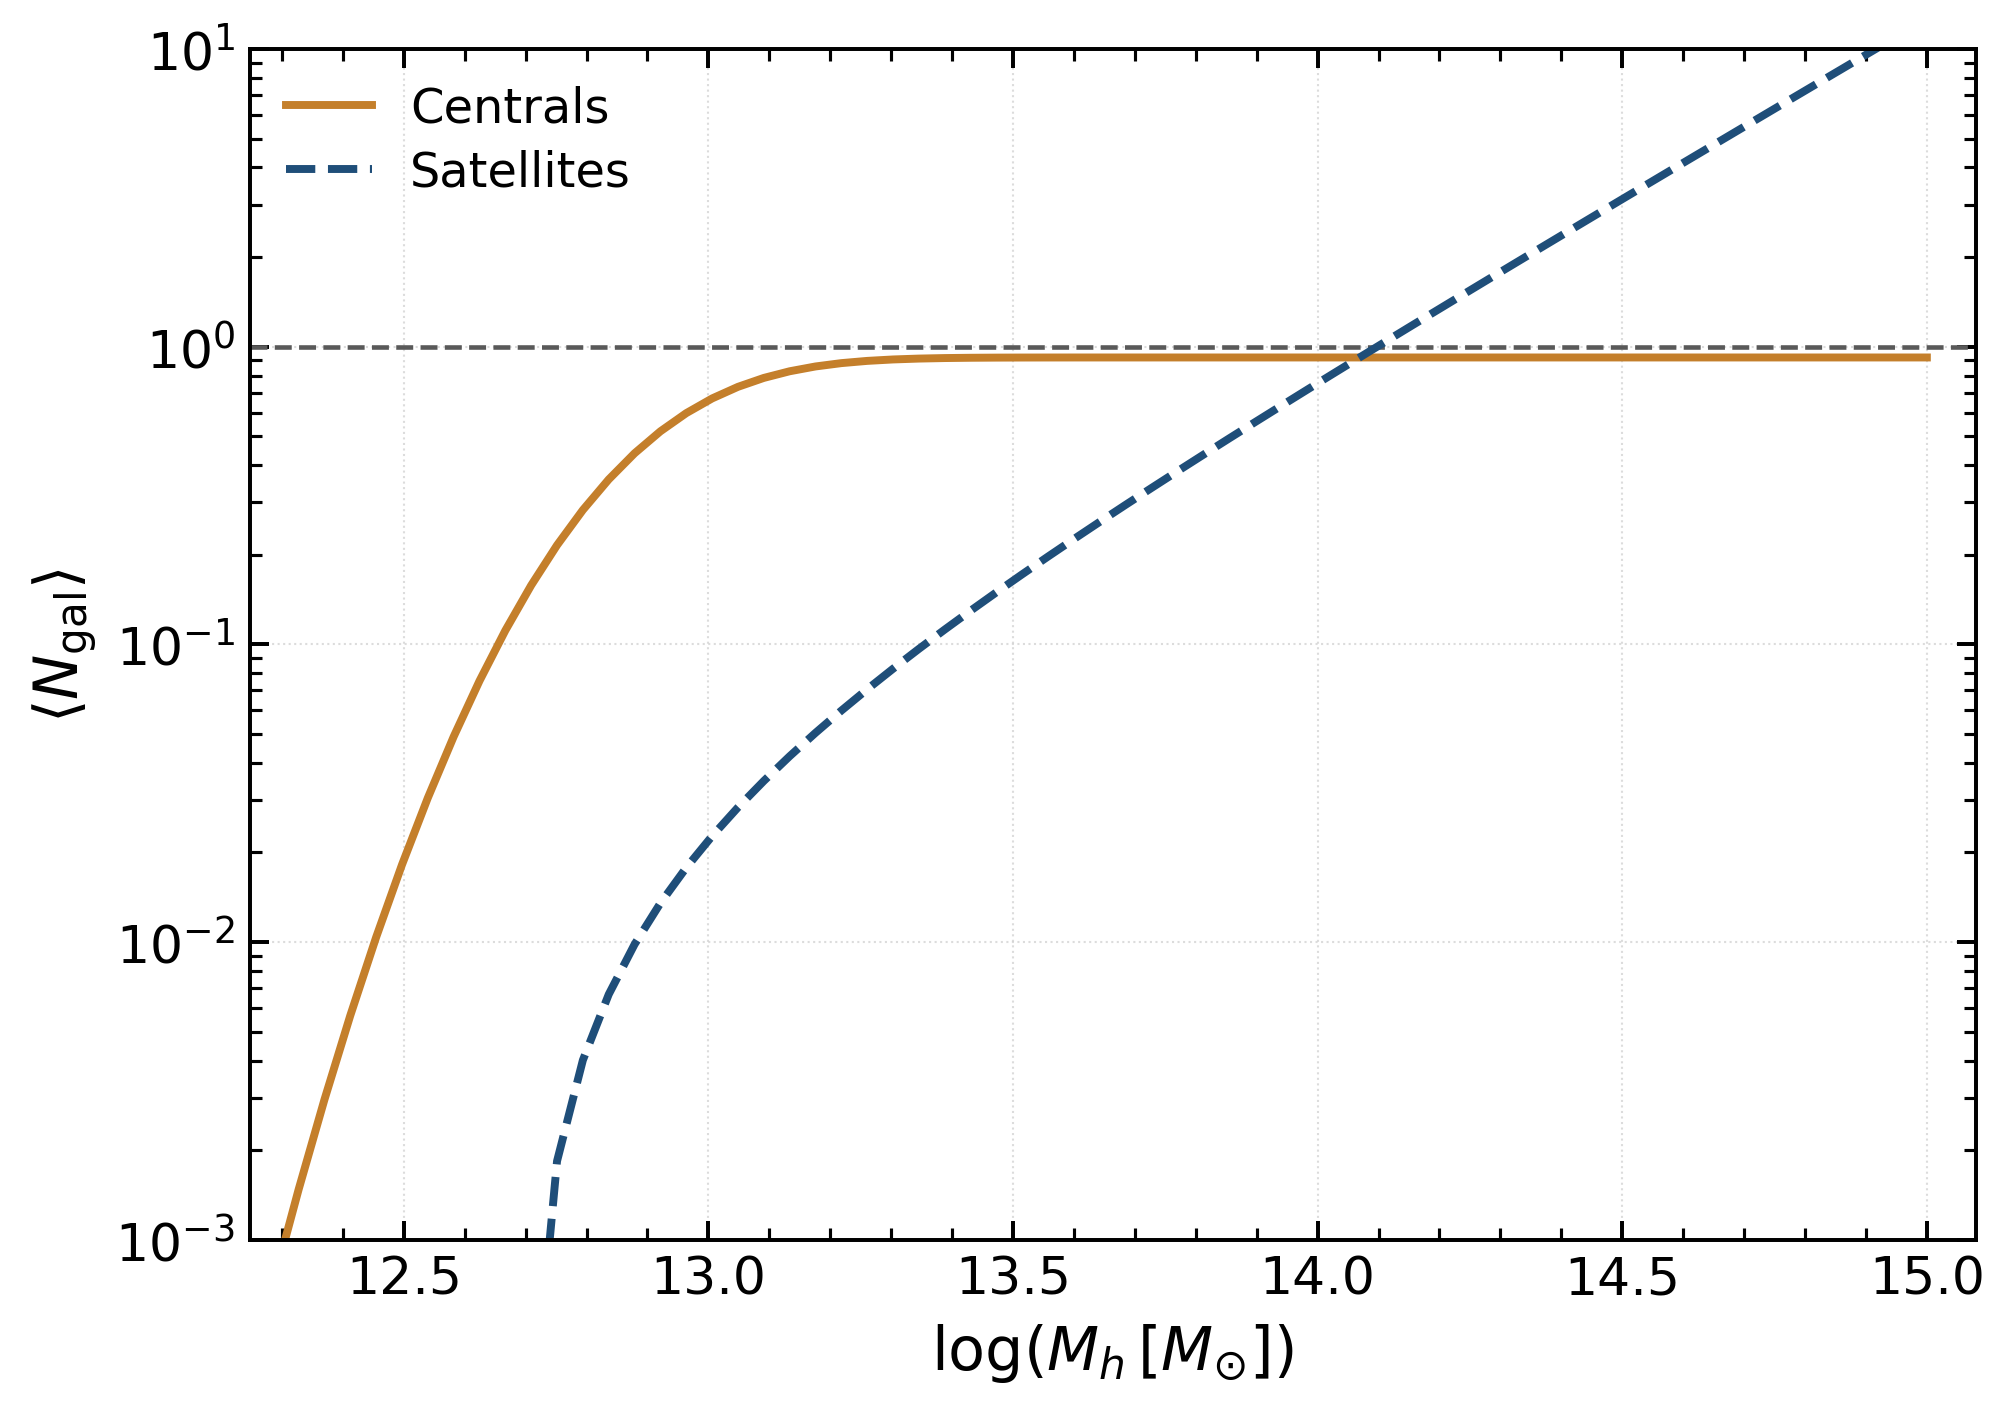

In [15]:
def plot_hod_styled(HOD_obj, tracer='LRG', logM=np.linspace(10.8, 15, 100)):
    pc, ps, _ = HOD_obj._HOD__init_hod_param(tracer)
    cen = np.asarray([HOD_obj._fun_cHOD[tracer](lM, pc) for lM in logM])
    sat = np.nan_to_num([HOD_obj._fun_sHOD[tracer](lM, ps) for lM in logM])

    fig, ax = plt.subplots(figsize=FIG_SIZE, dpi=300, constrained_layout=True)

    ylim_low, ylim_high = 0.001, 10
    ax.axhline(y=1, ls='--', c=REF_COLOR, lw=1.1)
    ax.plot(logM, cen, lw=LINE_WIDTH, color=COLA_COLOR, label='Centrals')
    ax.plot(logM, sat, lw=LINE_WIDTH, ls='--', color=BART_COLOR, label='Satellites')

    ax.set_yscale('log')
    ax.set_ylim(ylim_low, ylim_high)
    ax.set_xlabel(r'$\log(M_h\,[M_{\odot}])$', fontsize=LABEL_SIZE)
    ax.set_ylabel(r'$\langle N_{\mathrm{gal}} \rangle$', fontsize=LABEL_SIZE)
    ax.legend(fontsize=LEGEND_SIZE, frameon=False, handlelength=1.8, borderaxespad=0.35, labelspacing=0.35)

    visible = (cen > ylim_low) | (sat > ylim_low)
    xmin = logM[visible].min() if visible.any() else logM.min()
    pad = 0.03 * (logM.max() - xmin)
    ax.set_xlim(xmin - pad, logM.max() + pad)

    style_axis(ax)
    plt.show()


plot_hod_styled(HOD_obj, tracer='LRG')

In [16]:
rp, wp = HOD_obj.get_wp(cat, tracers='LRG')
s, xi = HOD_obj.get_2PCF(cat, tracers='LRG')

#Compute wp for LRG...


Done in 2.149 s


#Compute xi(s,mu) using l=[0, 2] for LRG...


#Done in 1.306 s


In [17]:
HOD_obj.args['LRG']['link_sat_to_central'] = True

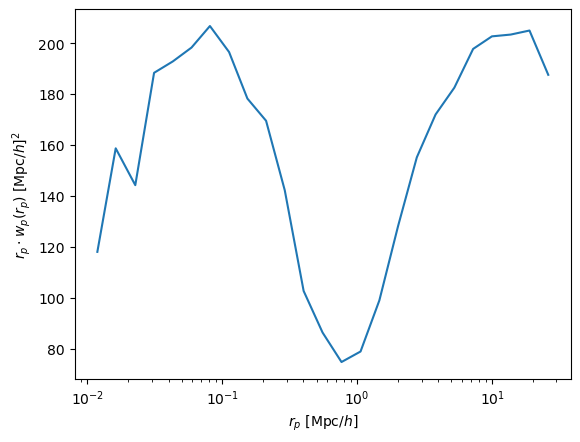

In [18]:
plt.plot(rp,rp*wp)
plt.xscale('log')
plt.xlabel('$r_p$ [$\mathrm{{Mpc}}/h$]')
plt.ylabel(r'$r_p \cdot w_p(r_p)$ [$\mathrm{{Mpc}}/h$]$^2$')
plt.show()

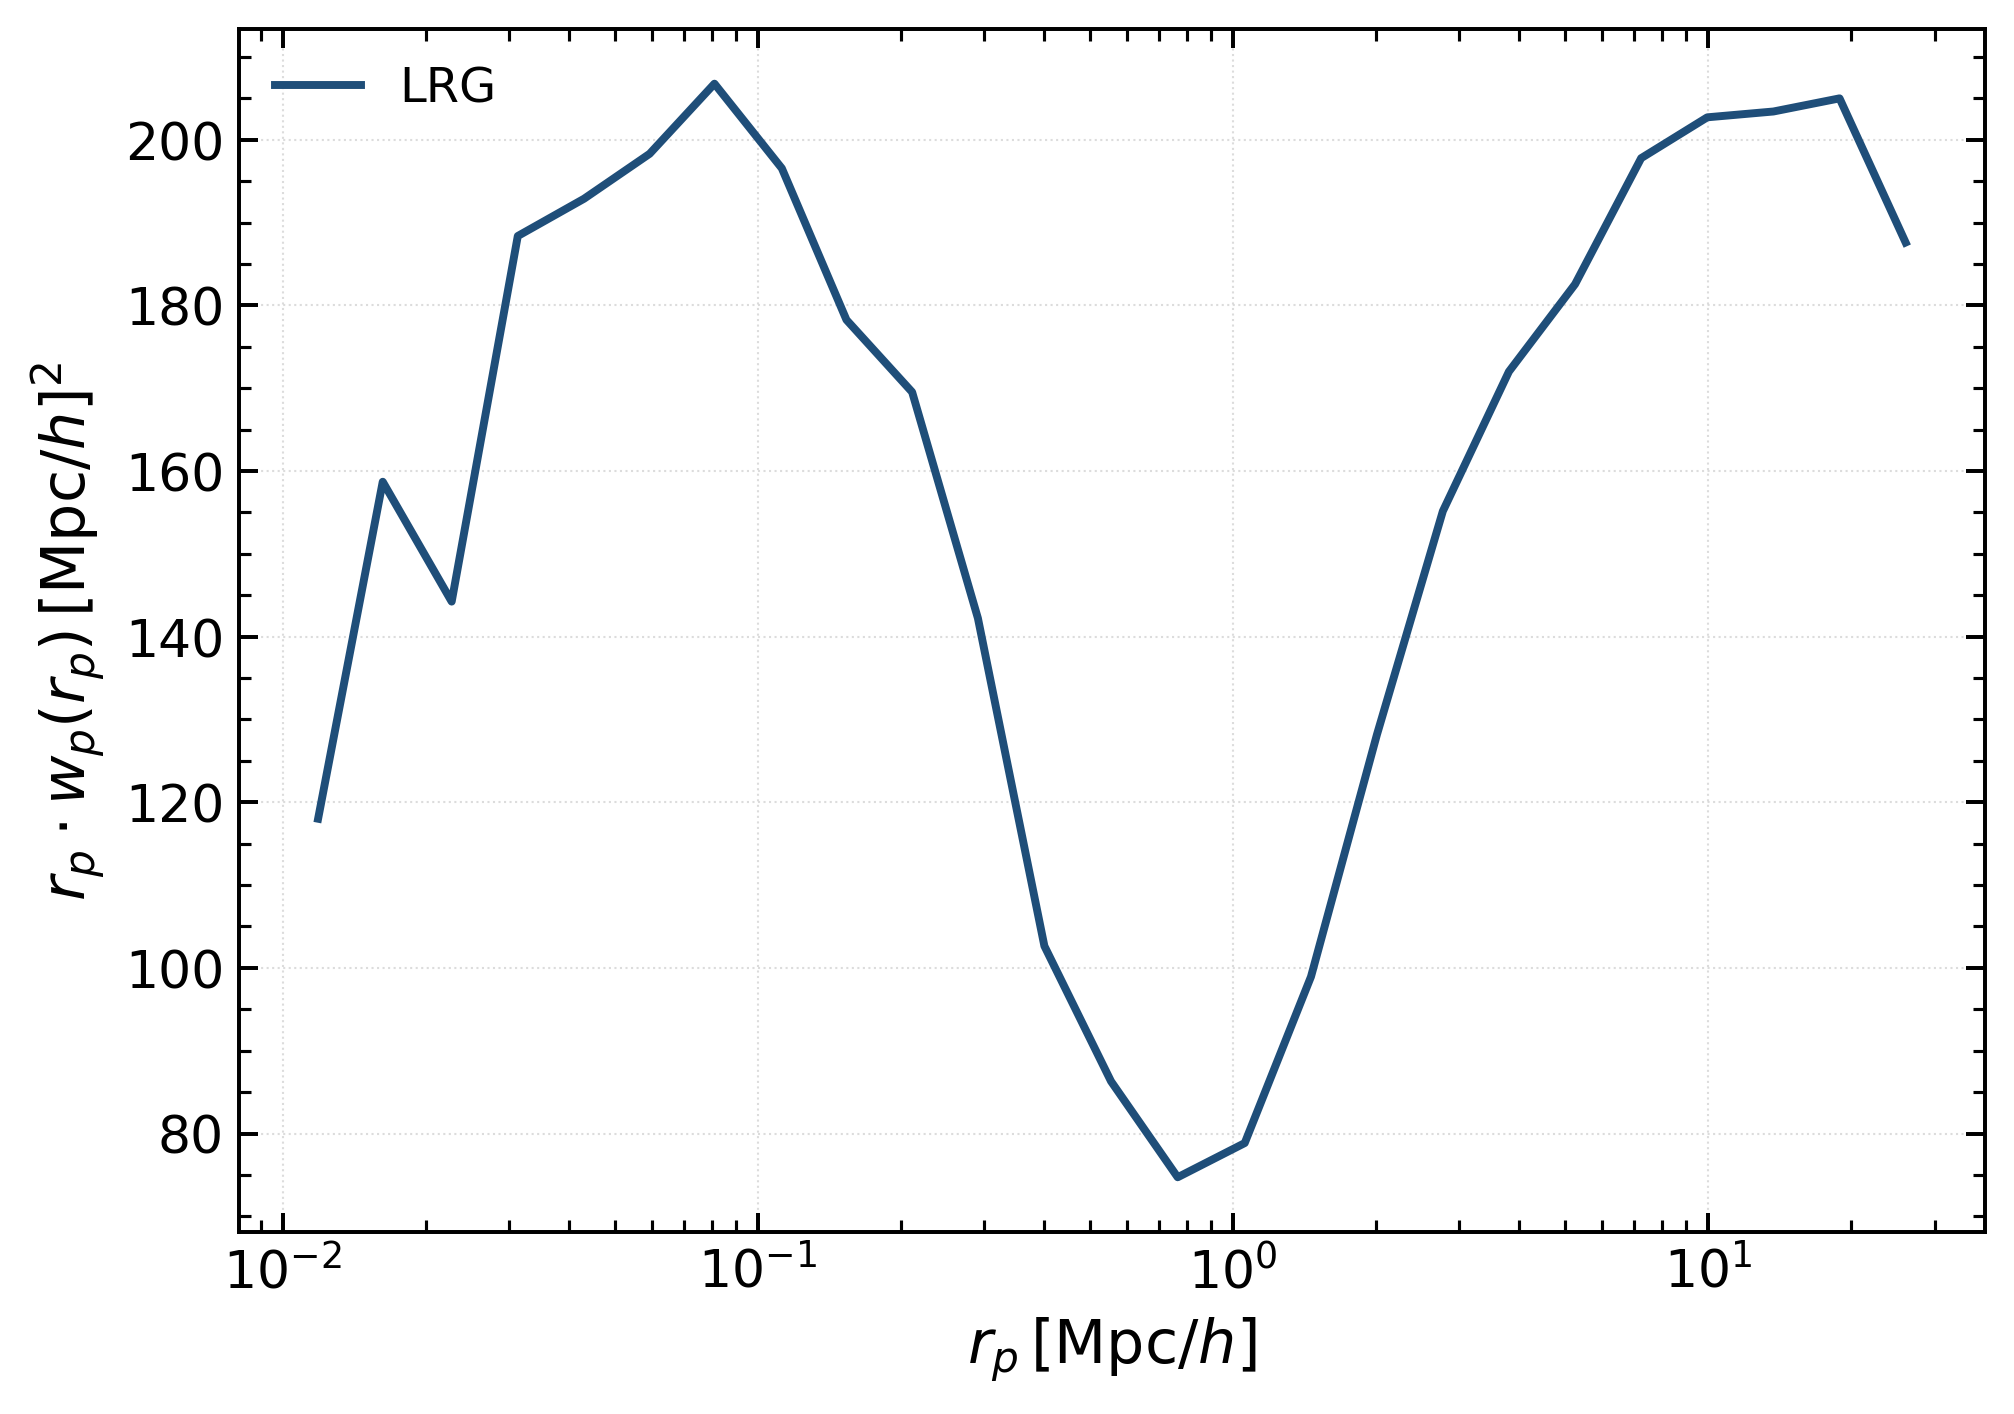

In [19]:
def plot_wp_styled(rp, wp, label='LRG'):
    fig, ax = plt.subplots(figsize=FIG_SIZE, dpi=300, constrained_layout=True)
    ax.semilogx(rp, rp * wp, lw=LINE_WIDTH, color=BART_COLOR, label=label)
    ax.set_xlabel(r'$r_p\,[\mathrm{Mpc}/h]$', fontsize=LABEL_SIZE)
    ax.set_ylabel(r'$r_p \cdot w_p(r_p)\,[\mathrm{Mpc}/h]^2$', fontsize=LABEL_SIZE)
    ax.legend(fontsize=LEGEND_SIZE, frameon=False, handlelength=1.8, borderaxespad=0.35, labelspacing=0.35)
    style_axis(ax)
    plt.show()


plot_wp_styled(rp, wp, label='LRG')

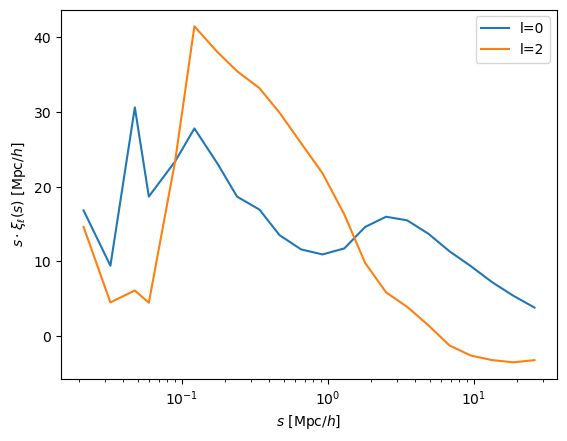

In [20]:
plt.plot(s,s*xi[0], label='l=0')
plt.plot(s,s*xi[1], label='l=2')
plt.xscale('log')
plt.xlabel('$s$ [$\mathrm{{Mpc}}/h$]')
plt.ylabel(r'$s \cdot \xi_{\ell}(s)$ [$\mathrm{{Mpc}}/h$]')
plt.legend()
plt.show()

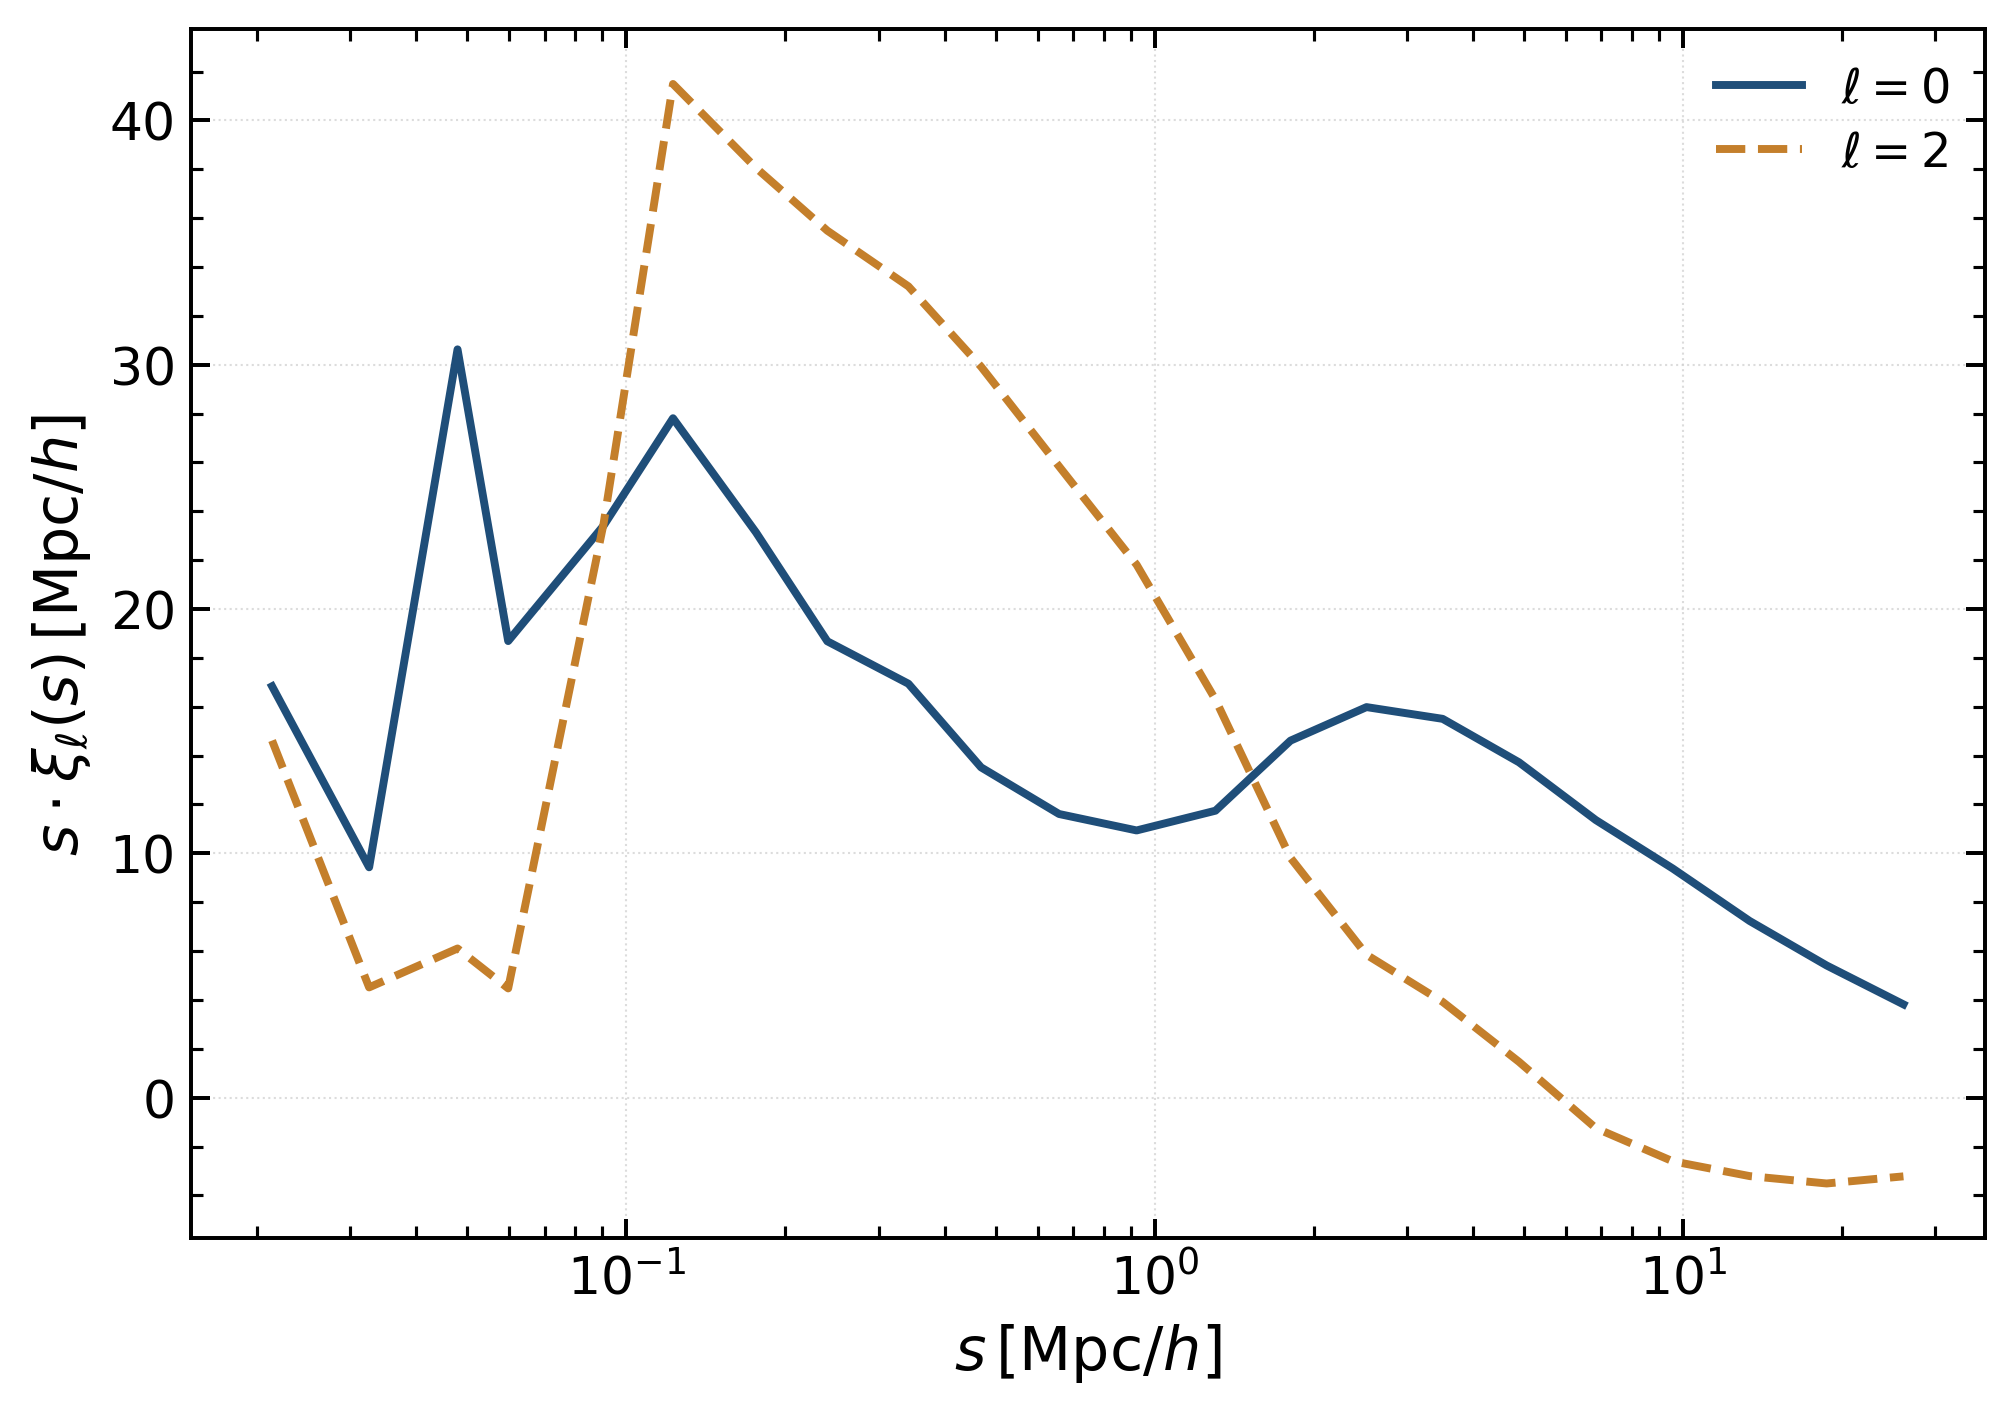

In [21]:
def plot_xi_styled(s, xi):
    fig, ax = plt.subplots(figsize=FIG_SIZE, dpi=300, constrained_layout=True)
    ax.semilogx(s, s * xi[0], lw=LINE_WIDTH, color=BART_COLOR, label=r'$\ell=0$')
    ax.semilogx(s, s * xi[1], lw=LINE_WIDTH, ls='--', color=COLA_COLOR, label=r'$\ell=2$')
    ax.set_xlabel(r'$s\,[\mathrm{Mpc}/h]$', fontsize=LABEL_SIZE)
    ax.set_ylabel(r'$s \cdot \xi_{\ell}(s)\,[\mathrm{Mpc}/h]$', fontsize=LABEL_SIZE)
    ax.legend(fontsize=LEGEND_SIZE, frameon=False, handlelength=1.8, borderaxespad=0.35, labelspacing=0.35)
    style_axis(ax)
    plt.show()


plot_xi_styled(s, xi)

## LRG power spectrum (FFT, nbodykit)

In [22]:
from nbodykit.lab import ArrayCatalog, FFTPower


def compute_lrg_pk(cat, boxsize, tracer='LRG', nmesh=256, dk=None, kmin=0.0, subtract_shotnoise=True):
    mask = cat['TRACER'] == tracer
    pos = np.column_stack([
        cat['x'][mask] % boxsize,
        cat['y'][mask] % boxsize,
        cat['z'][mask] % boxsize,
    ]).astype('f4')

    galaxy_cat = ArrayCatalog({'Position': pos})
    mesh = galaxy_cat.to_mesh(Nmesh=nmesh, BoxSize=boxsize, resampler='tsc',
                               interlaced=True, compensated=True)
    result = FFTPower(mesh, mode='1d', dk=dk or 2 * np.pi / boxsize, kmin=kmin)

    k = result.power['k']
    Pk = result.power['power'].real
    if subtract_shotnoise:
        Pk = Pk - result.power.attrs['shotnoise']

    valid = k > 0  # drop the k=0 DC bin
    return k[valid], Pk[valid]


def plot_lrg_pk_styled(k, Pk, label='LRG'):
    fig, ax = plt.subplots(figsize=FIG_SIZE, dpi=300, constrained_layout=True)
    ax.loglog(k, Pk, lw=LINE_WIDTH, color=BART_COLOR, label=label)
    ax.set_xlabel(r'$k\,[h\,\mathrm{Mpc}^{-1}]$', fontsize=LABEL_SIZE)
    ax.set_ylabel(r'$P(k)\,[(\mathrm{Mpc}/h)^3]$', fontsize=LABEL_SIZE)
    ax.legend(fontsize=LEGEND_SIZE, frameon=False, handlelength=1.8, borderaxespad=0.35, labelspacing=0.35)
    style_axis(ax)
    plt.show()

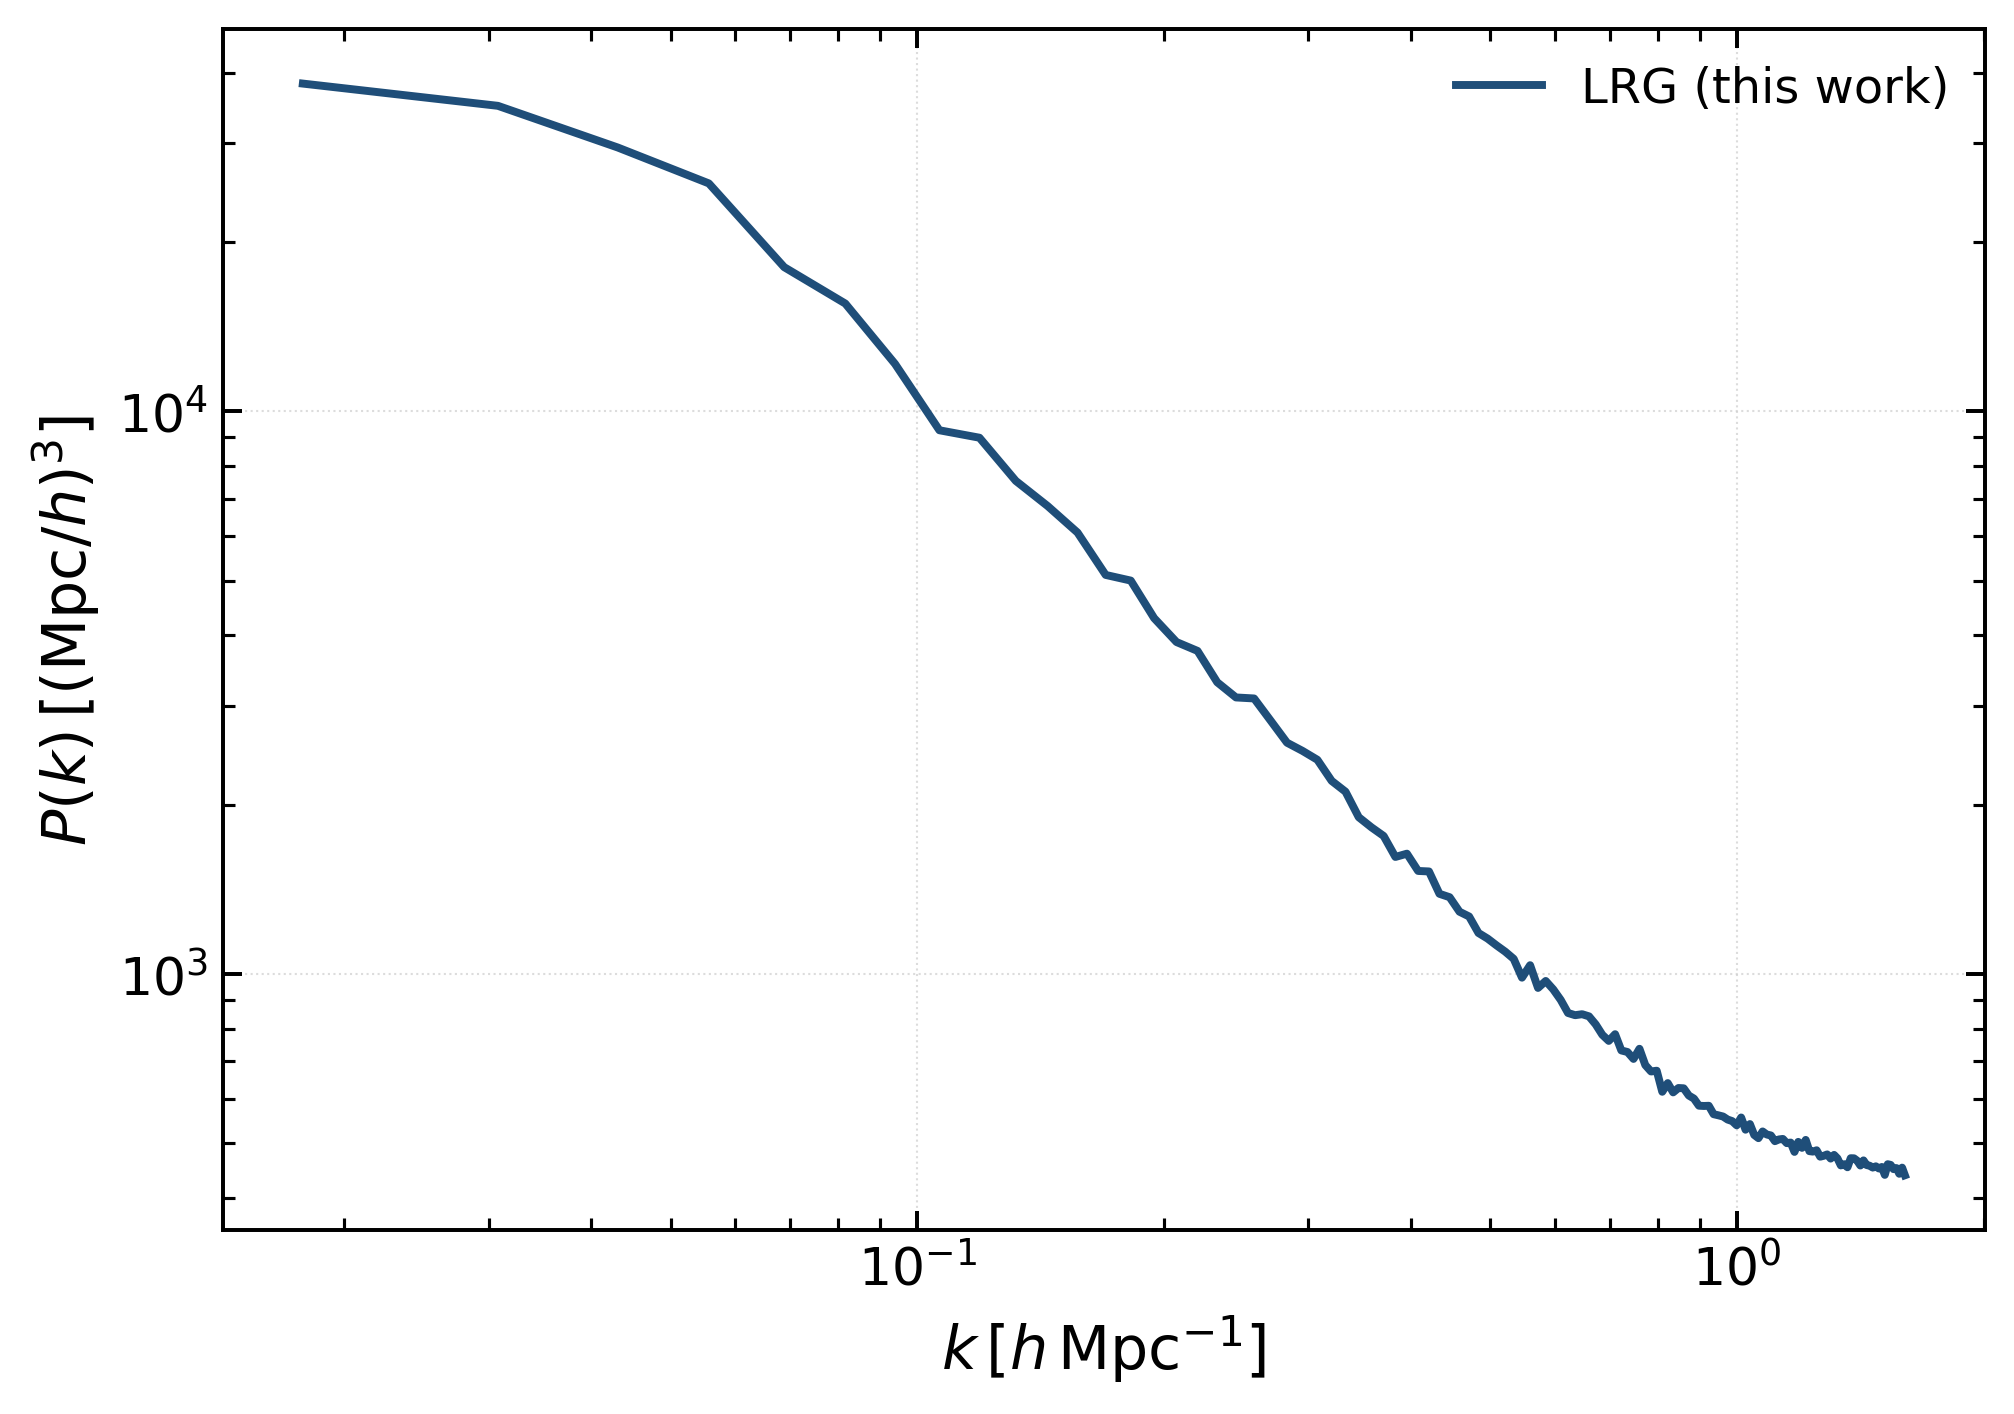

In [23]:
k_lrg, Pk_lrg = compute_lrg_pk(cat, HOD_obj.boxsize, tracer='LRG')
plot_lrg_pk_styled(k_lrg, Pk_lrg, label='LRG (this work)')